Number of masks: 3725
Number of without masks: 3828


/Users/phamgiaminh/Library/Python/3.9/lib/python/site-packages/PIL/Image.py:1056: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/Users/phamgiaminh/Library/Python/3.9/lib/python/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


170/170 ━━━━━━━━━━━━━━━━━━━━ 22s 122ms/step - accuracy: 0.7432 - loss: 0.5782 - val_accuracy: 0.8777 - val_loss: 0.3093
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.8724 - loss: 0.2997
Test accuracy: 0.8888153433799744


KeyError: 'acc'

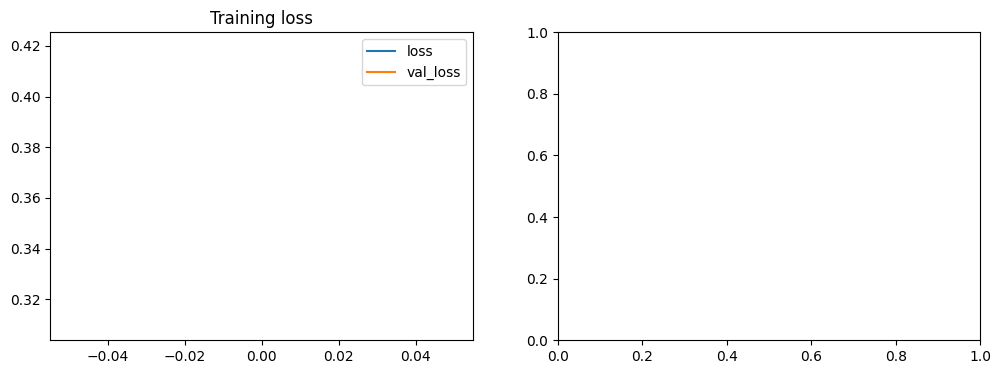

In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2
from sklearn.model_selection import train_test_split
from tensorflow import keras

#Setup the data and files
with_mask_path = os.path.join('data', 'with_mask')
without_mask_path = os.path.join('data', 'without_mask')

with_mask_files = os.listdir(with_mask_path)
without_mask_files = os.listdir(without_mask_path)

print("Number of masks:", len(with_mask_files))
print("Number of without masks:", len(without_mask_files))

#Create the labels(1 = mask, 0 = no mask)
with_mask_labels = [1] * len(with_mask_files)
without_mask_labels = [0] * len(without_mask_files)
labels = with_mask_labels + without_mask_labels

#Preprocess our images
data = []
for file in with_mask_files:
    image = Image.open(os.path.join(with_mask_path, file))
    image = image.resize((128, 128))
    image = image.convert("RGB")
    image = np.array(image)
    data.append(image)
for file in without_mask_files:
    image = Image.open(os.path.join(without_mask_path, file))
    image = image.resize((128, 128))
    image = image.convert("RGB")
    image = np.array(image)
    data.append(image)

# print(data[0][0][0])

X = np.array(data)
y = np.array(labels)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

X_train_scaled = X_train/255
X_test_scaled = X_test/255

#Build the model
num_classes = 2
model = keras.Sequential([
    #first layer
    keras.layers.Conv2D(32, kernel_size = (3,3), activation = 'relu', input_shape = (128, 128, 3)),
    keras.layers.MaxPooling2D(pool_size = (2,2)),
    #second layer
    keras.layers.Conv2D(64, kernel_size = (3,3), activation = 'relu', input_shape = (128, 128, 3)),
    keras.layers.MaxPooling2D(pool_size = (2,2)),

    keras.layers.Flatten(),
    #third layer
    keras.layers.Dense(128, activation = 'relu'),
    keras.layers.Dropout(0.5),

    keras.layers.Dense(64, activation = 'relu'),
    keras.layers.Dropout(0.5),
    #output layer
    keras.layers.Dense(num_classes, activation = 'sigmoid')
])
model.compile(
    optimizer = 'adam',
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)
#Train the model
history = model.fit(X_train_scaled, y_train, validation_split = 0.1, epochs = 1)
loss, accuracy = model.evaluate(X_test_scaled, y_test)
print("Test accuracy:", accuracy)

#Plot
plt.figure(figsize = (12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label = 'loss')
plt.plot(history.history['val_loss'], label = 'val_loss')
plt.legend()
plt.title("Training loss")

plt.subplot(1, 2, 2)
plt.plot(history.history['acc'], label = 'accuracy')
plt.plot(history.history['val_acc'], label = 'val accuracy')
plt.legend()
plt.title("Training accuracy")

plt.show()



